In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Logistic Regression model
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

In [3]:
# Load dataset
df = pd.read_csv("/content/Telco-Customer-Churn.csv")

# Display first rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Fill missing values
df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

# Remove customerID
df.drop("customerID", axis=1, inplace=True)

/tmp/ipykernel_1671/3861160474.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)


In [5]:
# Encode categorical features
encoder = LabelEncoder()

for column in df.columns:
    if df[column].dtype == "object":
        df[column] = encoder.fit_transform(df[column])

In [6]:
# Split features and target
X = df.drop("Churn", axis=1)

y = df["Churn"]

In [7]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [8]:
# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [9]:
# Train Logistic Regression
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [10]:
# Predict classes
y_pred = model.predict(X_test)

# Predict probabilities
y_prob = model.predict_proba(X_test)[:,1]

In [11]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[933 103]
 [157 216]]


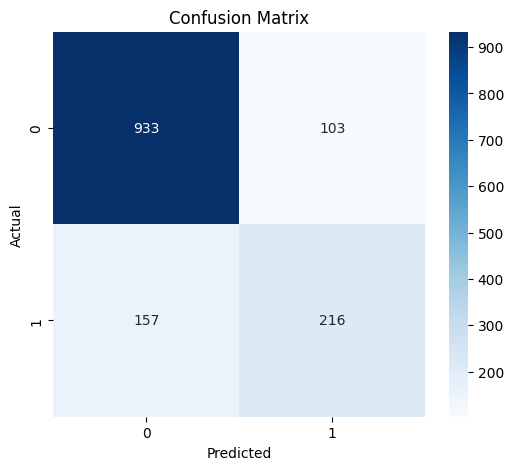

In [12]:
# Plot confusion matrix

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [13]:
# Extract confusion matrix values

TN = cm[0,0]

FP = cm[0,1]

FN = cm[1,0]

TP = cm[1,1]

# Calculate Precision
precision = TP / (TP + FP)

# Calculate Recall
recall = TP / (TP + FN)

# Calculate F1 Score
f1 = 2 * (precision * recall) / (precision + recall)

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

Precision: 0.677115987460815
Recall: 0.579088471849866
F1 Score: 0.624277456647399


In [14]:
# Display classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.58      0.62       373

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.82      0.81      1409



In [15]:
# Compare manual metrics with sklearn metrics

comparison = pd.DataFrame({

    "Metric":[
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Manual":[
        precision,
        recall,
        f1
    ],

    "Scikit-Learn":[
        precision_score(y_test,y_pred),
        recall_score(y_test,y_pred),
        f1_score(y_test,y_pred)
    ]

})

comparison

,Metric,Manual,Scikit-Learn
0,Precision,0.677116,0.677116
1,Recall,0.579088,0.579088
2,F1 Score,0.624277,0.624277


In [16]:
# Calculate ROC values

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

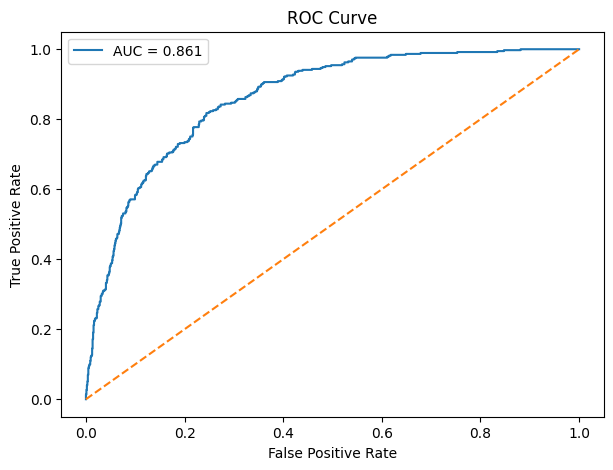

In [17]:
# Plot ROC Curve

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [18]:
# Display AUC score

print("AUC Score:", auc)

AUC Score: 0.861354508472471


In [19]:
# Predictions with threshold 0.3

pred03 = (y_prob >= 0.3).astype(int)

print(classification_report(y_test, pred03))

              precision    recall  f1-score   support

           0       0.92      0.76      0.83      1036
           1       0.55      0.81      0.65       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.82      0.77      0.78      1409



In [20]:
# Predictions with threshold 0.7

pred07 = (y_prob >= 0.7).astype(int)

print(classification_report(y_test, pred07))

              precision    recall  f1-score   support

           0       0.77      0.99      0.86      1036
           1       0.82      0.18      0.29       373

    accuracy                           0.77      1409
   macro avg       0.79      0.58      0.58      1409
weighted avg       0.78      0.77      0.71      1409



In [21]:
# Compare thresholds

threshold_table = pd.DataFrame({

    "Threshold":[0.3,0.5,0.7],

    "Precision":[
        precision_score(y_test,pred03),
        precision_score(y_test,y_pred),
        precision_score(y_test,pred07)
    ],

    "Recall":[
        recall_score(y_test,pred03),
        recall_score(y_test,y_pred),
        recall_score(y_test,pred07)
    ]

})

threshold_table

,Threshold,Precision,Recall
0,0.3,0.546279,0.806971
1,0.5,0.677116,0.579088
2,0.7,0.817073,0.179625


In [22]:
# Threshold analysis

print("Threshold = 0.3 increases Recall but may reduce Precision.")

print("Threshold = 0.7 increases Precision but may reduce Recall.")

print("Threshold = 0.5 provides a balance between Precision and Recall.")

print("Choosing the threshold depends on the application requirements.")

Threshold = 0.3 increases Recall but may reduce Precision.
Threshold = 0.7 increases Precision but may reduce Recall.
Threshold = 0.5 provides a balance between Precision and Recall.
Choosing the threshold depends on the application requirements.
